# Predicting ChlorA (Chlorophyll-a) — CalCOFI

**Goal:** Build a regression model to predict `ChlorA` (µg/L chlorophyll-a) from bottle + cast oceanographic features.

This notebook starts with data loading, field descriptions, joining on `Cst_Cnt`, and exploratory analysis.

## 1. Imports & load data

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)

DATA_DIR = "../data"
OUT_DIR = Path("model_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42


In [2]:
# Bottle = per-depth water samples; Cast = per-station cast metadata
bottle = pd.read_csv(f"{DATA_DIR}/bottle.csv", encoding="iso-8859-1", low_memory=False)
cast = pd.read_csv(f"{DATA_DIR}/cast.csv", encoding="iso-8859-1", low_memory=False)

print(f"bottle shape: {bottle.shape}")
print(f"cast shape:   {cast.shape}")
display(bottle.head(3))
display(cast.head(3))

bottle shape: (895371, 62)
cast shape:   (35644, 61)


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,C14A2q,DarkAs,DarkAp,DarkAq,MeanAs,MeanAp,MeanAq,IncTim,LightP,R_Depth,R_TEMP,R_Sal,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,0.0,10.50,233.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,8.0,10.46,232.5,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,10.0,10.46,232.8,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Cst_Cnt,Cruise_ID,Cruise,Cruz_Sta,DbSta_ID,Cast_ID,Sta_ID,Quarter,Sta_Code,Distance,Date,Year,Month,Julian_Date,Julian_Day,Time,Lat_Dec,Lat_Deg,Lat_Min,Lat_Hem,Lon_Dec,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1949-03-01-C-31CR,194903,19490305400560,5400560,19-4903CR-HY-060-0930-05400560,054.0 056.0,1,NST,NaN,03/01/1949,1949,3,17958,60,09:30:00,38.833333,38,50.0,N,-124.083333,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,2,1949-03-01-C-31CR,194903,19490305200750,5200750,19-4903CR-HY-060-2112-05200750,052.0 075.0,1,NST,NaN,03/01/1949,1949,3,17958,60,21:12:00,38.583333,38,35.0,N,-125.800000,-125,48.0,W,52.0,52.0,51.5,75.0,75.0,75.1,NaN,NaN,NaN,CREST,31CR,HY,NaN,2.0,NaN,052 75,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0,5.0,NaN,NaN,NaN,4.0,NaN,NaN,NaN
2,3,1949-03-01-C-31CR,194903,19490305100850,5100850,19-4903CR-HY-061-0354-05100850,051.0 085.0,1,NST,NaN,03/02/1949,1949,3,17959,61,03:54:00,38.475000,38,28.5,N,-126.666666,-126,40.0,W,51.0,51.0,50.3,85.0,85.0,84.7,NaN,NaN,NaN,CREST,31CR,HY,NaN,3.0,NaN,051 85,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,5.0,NaN,NaN,NaN,6.0,NaN,NaN,NaN


## 2. Field descriptions

Lookup tables describing each column in the bottle and cast tables.

In [66]:
bottle_desc = pd.read_csv(f"{DATA_DIR}/Bottle Field Descriptions.csv", encoding="iso-8859-1")
cast_desc = pd.read_csv(f"{DATA_DIR}/Cast Field Descriptions.csv", encoding="iso-8859-1")

# Drop empty trailing columns if present
bottle_desc = bottle_desc.dropna(axis=1, how="all")
cast_desc = cast_desc.dropna(axis=1, how="all")

print("=== Bottle field descriptions ===")
display(bottle_desc)

print("=== Cast field descriptions ===")
display(cast_desc)

=== Bottle field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Btl_Cnt,n.a.,"Bottle Count - All CalCOFI bottles ever sampled, consecutively numbered"
2,Sta_ID,n.a.,Line and Station [Line] [Station]
3,Depth_ID,n.a.,Uses the Cast_ID prefix ([Century]-[Year][Month][ShipCode]-[CastType][Julian Day]-[CastTime]-[Line][Sta]) but adds t...
4,Depthm,meters,Bottle depth in meters
...,...,...,...
57,TA1,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution
58,TA2,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution (on a replicate sample)
59,pH1,pH scale,pH (the degree of acidity/alkalinity of a solution)
60,pH2,pH scale,pH (the degree of acidity/alkalinity of a solution) on a replicate sample


=== Cast field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Cruise_ID,n.a.,Cruise identifier [Year]-[Month]-[Day]-C-[Ship Code]
2,Cruise,n.a.,Cruise Name [Year][Month]
3,Cruz_Sta,n.a.,Cruise Name and Station [Year][Month][Line][Station]
4,DbSta_ID,n.a.,Line and Station
...,...,...,...
56,Cloud_Typ,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 0500"
57,Cloud_Amt,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 2700, in oktas"
58,Visibility,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 4300"
59,Secchi,meters,Secchi disk depth in meters


In [4]:
def whatis(field_name, fd):
        print(fd[fd['Field Name']==field_name]['Description'])

In [5]:
whatis('ChlorA',bottle_desc)

21    Migrograms Chlorophyll-a per liter seawater, measured fluorometrically
Name: Description, dtype: object


## 3. Join bottle cast on `Cst_Cnt`

Each cast can have many bottles (depths). We left-join cast metadata onto every bottle row.

In [61]:
# Drop overlapping columns from cast (except join key) so we don't create _x/_y suffixes
overlap = [c for c in cast.columns if c in bottle.columns and c != "Cst_Cnt"]
print("Overlapping columns (kept from bottle, cast versions dropped):", overlap)

cast_for_join = cast.drop(columns=overlap)
df = bottle.merge(cast_for_join, on="Cst_Cnt", how="left")

print(f"\nJoined shape: {df.shape}")
print(f"Rows with ChlorA present: {df['ChlorA'].notna().sum():,} / {len(df):,}")
df.head(3)


Overlapping columns (kept from bottle, cast versions dropped): ['Sta_ID']

Joined shape: (895371, 121)
Rows with ChlorA present: 245,666 / 895,371


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN


## 4. Exploratory Data Analysis

We work with rows that have a measured `ChlorA` value. Quality-code / precision columns (`*q`, `*_qual`, `*_prec`) are dropped from the correlation view so the heatmap stays readable.

### 4.1 Correlation heatmap (numerical features)

In [7]:
whatis('DIC1',bottle_desc)

55    Dissolved Inorganic Carbon micromoles per kilogram solution
Name: Description, dtype: object


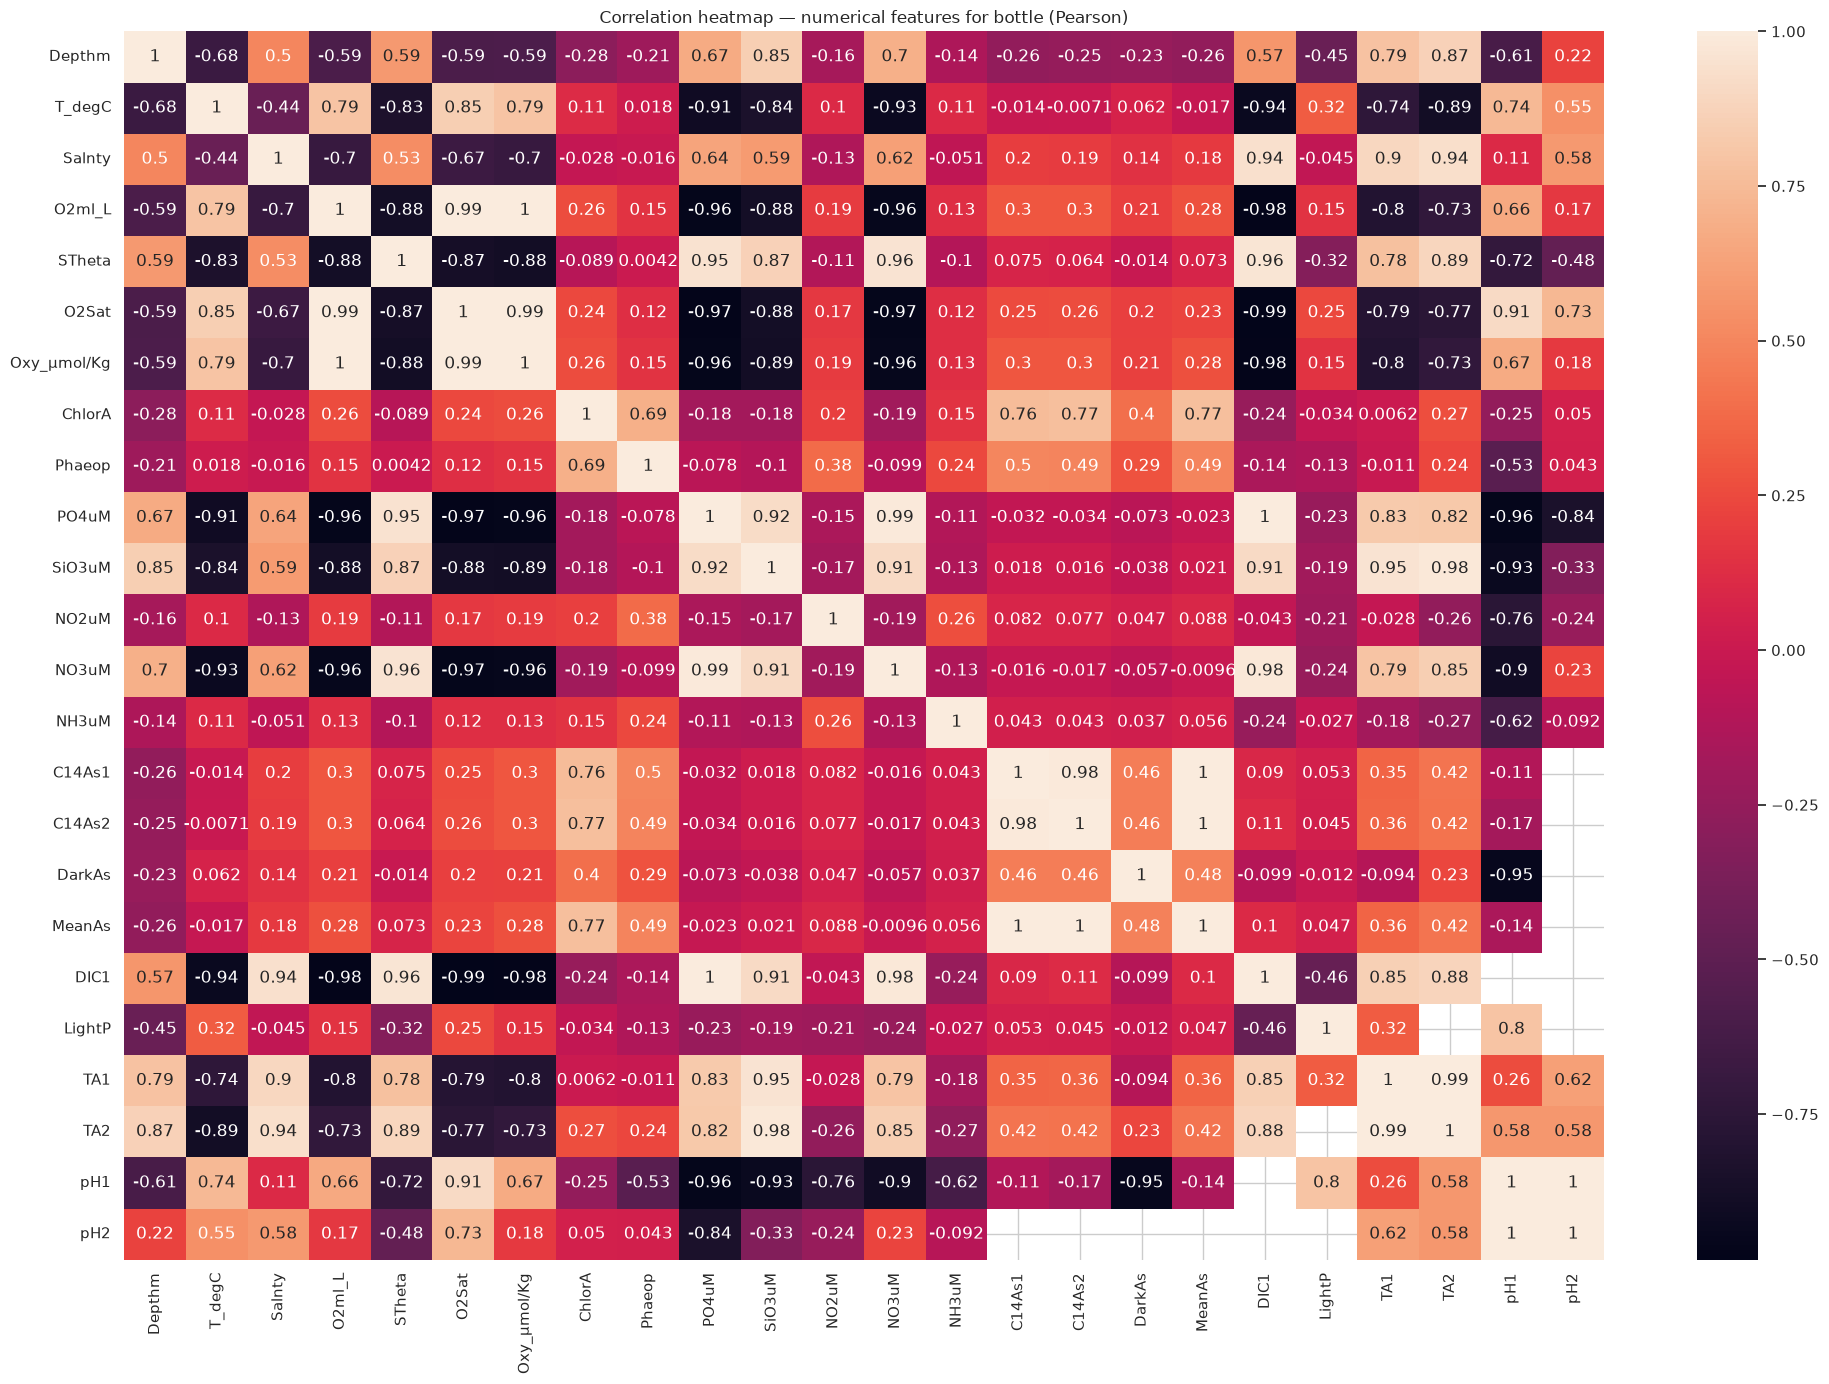

Top |correlations| with ChlorA:


,corr_with_ChlorA
C14As2,0.773470
MeanAs,0.769239
C14As1,0.755759
Phaeop,0.690607
DarkAs,0.401677
Depthm,-0.284359
TA2,0.265072
Oxy_µmol/Kg,0.260504
O2ml_L,0.257735
pH1,-0.252642


In [8]:
bottle_numeric_features = ['Depthm', 'T_degC',
       'Salnty', 'O2ml_L', 'STheta', 'O2Sat', 'Oxy_µmol/Kg','ChlorA', 'Phaeop','PO4uM',
       'SiO3uM',  'NO2uM',  'NO3uM','NH3uM',
       'C14As1', 'C14As2', 
       'DarkAs',  'MeanAs','DIC1', 
       'LightP', 'TA1', 'TA2', 'pH1', 'pH2']

corr = df[bottle_numeric_features].corr(method="pearson",numeric_only=True)

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    corr,
    annot=True

)
ax.set_title("Correlation heatmap — numerical features for bottle (Pearson)")
plt.tight_layout()
plt.show()

# ChlorA correlations ranked
if "ChlorA" in corr.columns:
    chlora_corr = corr["ChlorA"].drop("ChlorA").sort_values(key=abs, ascending=False)
    print("Top |correlations| with ChlorA:")
    display(chlora_corr.head(15).to_frame("corr_with_ChlorA"))


In [9]:
whatis('C14As2',bottle_desc)

38    14C Assimilation of Replicate 2 (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [10]:
whatis('MeanAs',bottle_desc)

44    Mean 14C Assimilation of Replicates 1 and 2 (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [11]:
whatis('Phaeop',bottle_desc)

23    Micrograms Phaeopigment per liter seawater, measured fluormetrically
Name: Description, dtype: object


In [12]:
whatis('DarkAs',bottle_desc)

41    14C Assimilation of Dark/Control Bottle (milligrams carbon per cubic meter of seawater per half light day)
Name: Description, dtype: object


In [13]:
whatis('TA2',bottle_desc)

58    Total Alkalinity micromoles per kilogram solution (on a replicate sample)
Name: Description, dtype: object


C14As2 : 14C Assimilation of Replicate 2 (milligrams carbon per cubic meter of seawater per half light day)

In [ ]:
sns.pairplot(df[bottle_numeric_features])

In [12]:
cast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35644 entries, 0 to 35643
Data columns (total 61 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Cst_Cnt      35644 non-null  int64  
 1   Cruise_ID    35644 non-null  object 
 2   Cruise       35644 non-null  int64  
 3   Cruz_Sta     35644 non-null  int64  
 4   DbSta_ID     35644 non-null  int64  
 5   Cast_ID      35644 non-null  object 
 6   Sta_ID       35644 non-null  object 
 7   Quarter      35644 non-null  int64  
 8   Sta_Code     35644 non-null  object 
 9   Distance     20954 non-null  float64
 10  Date         35644 non-null  object 
 11  Year         35644 non-null  int64  
 12  Month        35644 non-null  int64  
 13  Julian_Date  35644 non-null  int64  
 14  Julian_Day   35644 non-null  int64  
 15  Time         35320 non-null  object 
 16  Lat_Dec      35644 non-null  float64
 17  Lat_Deg      35644 non-null  int64  
 18  Lat_Min      35644 non-null  float64
 19  Lat_

In [13]:
whatis('IntChl',cast_desc)

40    Integrated Chlorophyll per half light day
Name: Description, dtype: object


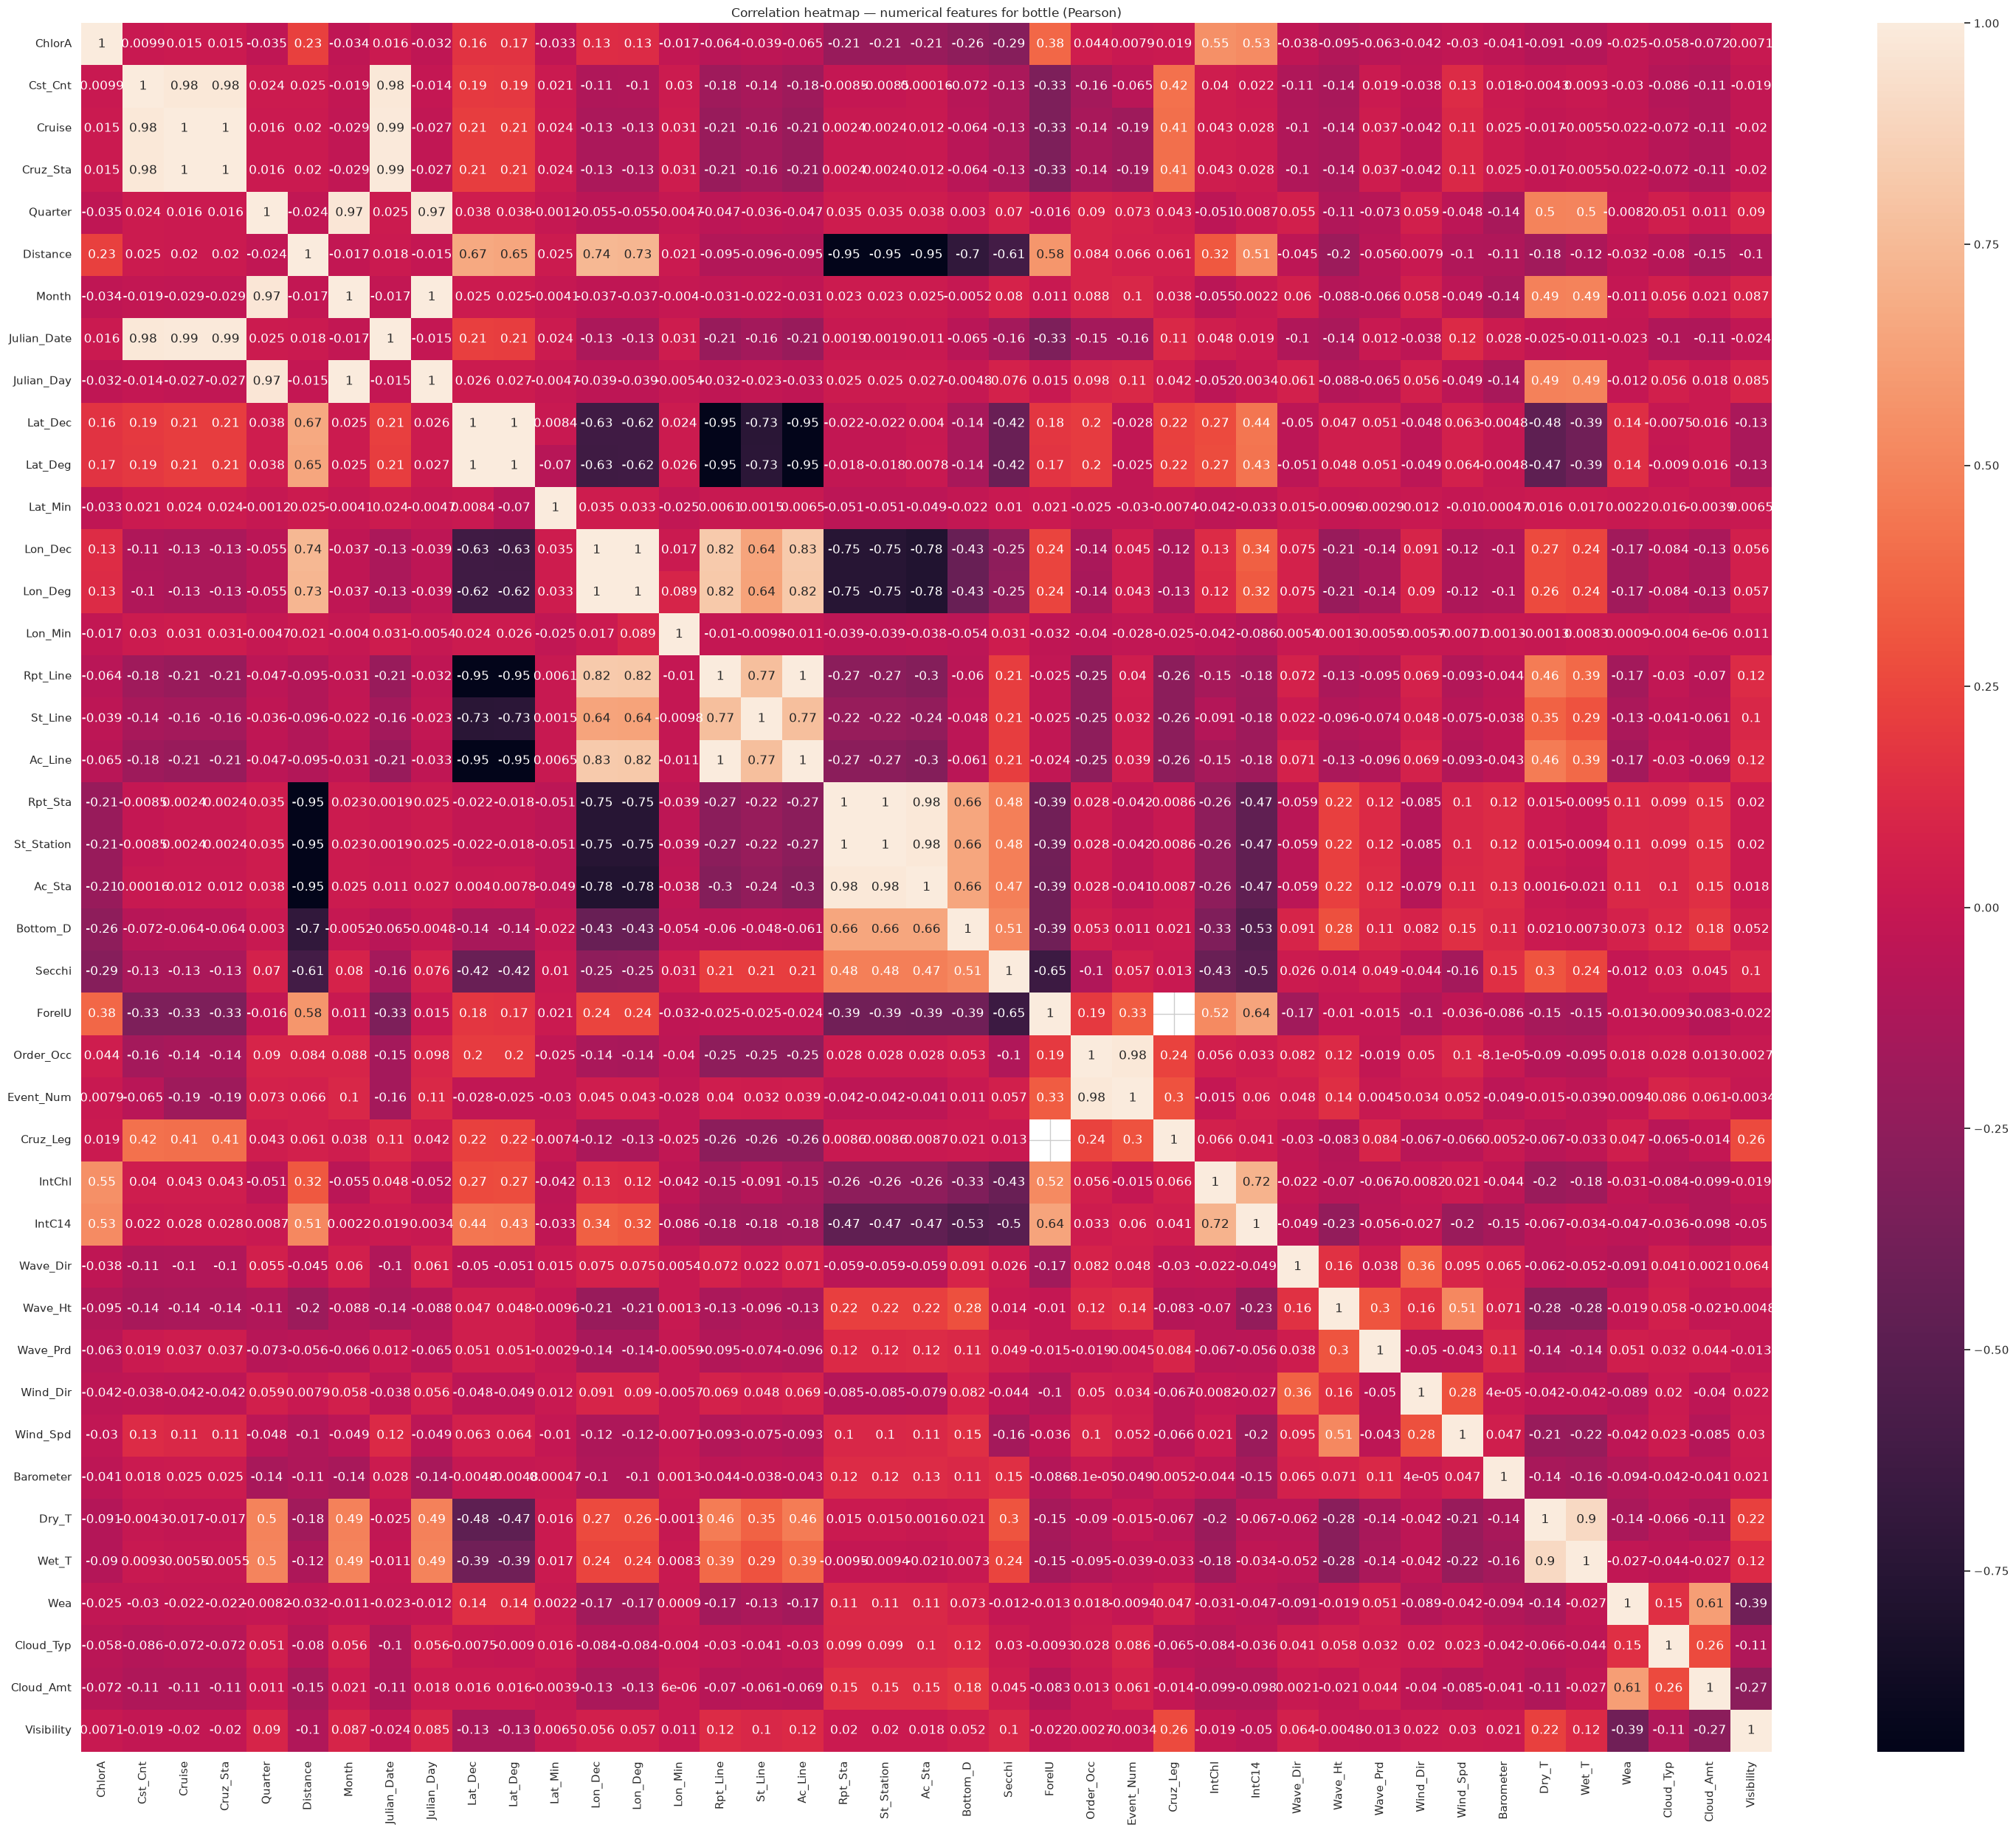

Top |correlations| with ChlorA:


,corr_with_ChlorA
IntChl,0.553275
IntC14,0.526864
ForelU,0.376568
Secchi,-0.292312
Bottom_D,-0.257508
Distance,0.225642
Ac_Sta,-0.207882
Rpt_Sta,-0.207412
St_Station,-0.207406
Lat_Deg,0.165302


In [14]:
cast_numeric_features = ['ChlorA','Cst_Cnt','Cruise', 'Cruz_Sta', 'Quarter', 'Sta_Code', 'Distance', 'Month',
       'Julian_Date', 'Julian_Day', 'Time', 'Lat_Dec', 'Lat_Deg', 'Lat_Min',
        'Lon_Dec', 'Lon_Deg', 'Lon_Min', 'Rpt_Line',
       'St_Line', 'Ac_Line', 'Rpt_Sta', 'St_Station', 'Ac_Sta', 'Bottom_D',
       'Secchi', 'ForelU', 'Ship_Name', 'Ship_Code', 'Data_Type', 'Order_Occ',
       'Event_Num', 'Cruz_Leg', 'Orig_Sta_ID', 'Data_Or', 'Cruz_Num', 'IntChl',
       'IntC14', 
       'Wave_Dir', 'Wave_Ht', 'Wave_Prd', 'Wind_Dir', 'Wind_Spd', 'Barometer',
       'Dry_T', 'Wet_T', 'Wea', 'Cloud_Typ', 'Cloud_Amt', 'Visibility']

corr = df[cast_numeric_features].corr(method="pearson",numeric_only=True)

fig, ax = plt.subplots(figsize=(30, 25))
sns.heatmap(
    corr,
    annot=True

)
ax.set_title("Correlation heatmap — numerical features for bottle (Pearson)")
plt.tight_layout()
plt.show()

# ChlorA correlations ranked
if "ChlorA" in corr.columns:
    chlora_corr = corr["ChlorA"].drop("ChlorA").sort_values(key=abs, ascending=False)
    print("Top |correlations| with ChlorA:")
    display(chlora_corr.head(15).to_frame("corr_with_ChlorA"))

In [15]:
whatis('IntChl',cast_desc)

40    Integrated Chlorophyll per half light day
Name: Description, dtype: object


In [16]:
whatis('IntC14',cast_desc)

41    Integrated Primary Productivity per half light day
Name: Description, dtype: object


In [17]:
whatis('ForelU',cast_desc)

60    Water color; Only used in CalCOFI dataset from 1988-10 through 1998-04
Name: Description, dtype: object


In [18]:
whatis('Secchi',cast_desc)

59    Secchi disk depth in meters
Name: Description, dtype: object


In [19]:
whatis('Bottom_D',cast_desc)

30    Bottom depth in meters
Name: Description, dtype: object


In [20]:
whatis('Wave_Ht',cast_desc)

48    Wave Height in feet
Name: Description, dtype: object


In [21]:
whatis('Dry_T',cast_desc)

53    Dry Air Temperature from a Sling Psychrometer in degrees Celcius
Name: Description, dtype: object


### 4.2 Distance from coast vs ChlorA (hue = Month)

`Distance` is nautical miles from the coast intercept (cast-level). Colored by calendar month to show seasonal structure.

In [ ]:
dist_plot = eda[["Distance", "ChlorA", "Month"]].dropna()
print(f"Rows with Distance + ChlorA + Month: {len(dist_plot):,}")

# Sample for readability if very large
if len(dist_plot) > 40_000:
    dist_plot = dist_plot.sample(40_000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Distance vs ChlorA, colored by month
sc = axes[0].scatter(
    dist_plot["Distance"],
    dist_plot["ChlorA"],
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
cb = fig.colorbar(sc, ax=axes[0], label="Month")
axes[0].set_xlabel("Distance from coast (nmi)")
axes[0].set_ylabel("ChlorA (µg/L)")
axes[0].set_title("Distance vs ChlorA (hue = Month)")

# Same relationship on log1p(ChlorA) — chlorophyll is heavily right-skewed
sc2 = axes[1].scatter(
    dist_plot["Distance"],
    np.log1p(dist_plot["ChlorA"]),
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
fig.colorbar(sc2, ax=axes[1], label="Month")
axes[1].set_xlabel("Distance from coast (nmi)")
axes[1].set_ylabel("log1p(ChlorA)")
axes[1].set_title("Distance vs log1p(ChlorA) (hue = Month)")

plt.tight_layout()
plt.show()

# Monthly summary
monthly = (
    eda.dropna(subset=["Distance", "ChlorA", "Month"])
    .groupby("Month")
    .agg(n=("ChlorA", "size"), mean_ChlorA=("ChlorA", "mean"), mean_Distance=("Distance", "mean"))
)
display(monthly)

## 5. Feature engineering & missing values

Fill NAs for the top ChlorA correlates, derive **Line / Station**, **NSM** (seconds since midnight), and one-hot encode **Month** and **Day**.


In [ ]:
# Resolve oxygen column names (mu character can vary by encoding)
def col_containing(df, *parts):
    for c in df.columns:
        if all(p in c for p in parts):
            return c
    raise KeyError(f"No column containing {parts}")

OXY_UMOL = col_containing(df, "Oxy_", "mol/Kg")
R_OXY_UMOL = col_containing(df, "R_Oxy")

TOP_CORR_FEATURES = [
    "Phaeop",
    R_OXY_UMOL,
    OXY_UMOL,
    "O2ml_L",
    "Depthm",
    "R_Depth",
    "R_DYNHT",
    "O2Sat",
    "SiO3uM",
    "NO3uM",
    "T_degC",
]

print("Top-correlation feature columns:")
for c in TOP_CORR_FEATURES:
    print(f"  {c!r}")

# Work only on rows with ChlorA target
model_df = df[df["ChlorA"].notna()].copy()

# --- Line & Station from Sta_ID ("090.0 045.0") ---
sta_parts = model_df["Sta_ID"].astype(str).str.strip().str.split(expand=True)
model_df["Line"] = pd.to_numeric(sta_parts[0], errors="coerce")
model_df["Station"] = pd.to_numeric(sta_parts[1], errors="coerce")

# --- Day of month from Date; NSM from Time ---
model_df["Date_parsed"] = pd.to_datetime(model_df["Date"], errors="coerce")
model_df["Day"] = model_df["Date_parsed"].dt.day

def time_to_nsm(t):
    """Number of Seconds since Midnight."""
    if pd.isna(t):
        return np.nan
    try:
        parts = str(t).split(":")
        h, m = int(parts[0]), int(parts[1])
        s = float(parts[2]) if len(parts) > 2 else 0.0
        return h * 3600 + m * 60 + s
    except Exception:
        return np.nan

model_df["NSM"] = model_df["Time"].map(time_to_nsm)

print(f"Rows with ChlorA: {len(model_df):,}")
print("NA rates (before impute) for top correlates + time/location:")
display(
    model_df[TOP_CORR_FEATURES + ["Line", "Station", "Month", "Day", "NSM"]]
    .isna().mean()
    .sort_values(ascending=False)
    .to_frame("frac_na")
)

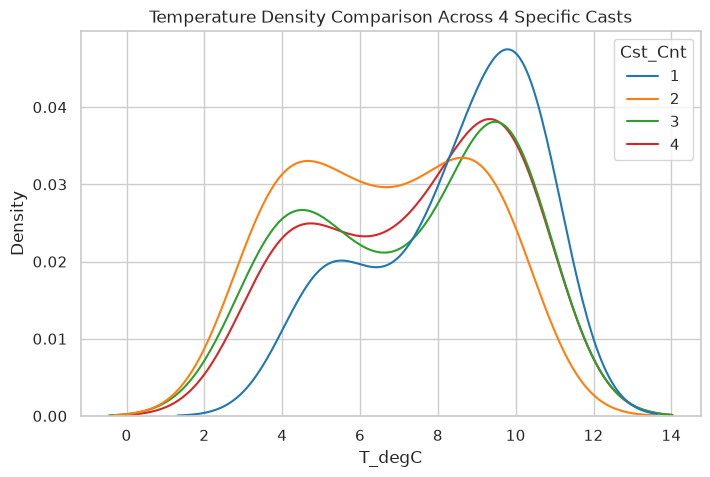

In [47]:
# Select 4 specific casts
selected_casts = df['Cst_Cnt'].unique()[:4]
subset = df[df['Cst_Cnt'].isin(selected_casts)]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=subset, x="T_degC", hue="Cst_Cnt", palette="tab10")
plt.title("Temperature Density Comparison Across 4 Specific Casts")
plt.show()

In [67]:
df.shape

(895371, 121)

In [81]:
df['T_degC'].isna().sum()/df.shape[0]

np.float64(0.012250787662320982)

In [112]:
df['T_degC'] = df.groupby('Cst_Cnt')['T_degC'].transform(lambda group: group.interpolate(method='linear',limit_direction='both'))

In [118]:
df['T_degC'].isna().sum()

np.int64(2683)

In [113]:
# Select 4 specific casts
selected_casts = df[df['T_degC'].isna()]['Cst_Cnt']
subset = df[df['Cst_Cnt'].isin(selected_casts)]

print(subset['T_degC'].unique()) 
print(subset['Ship_Name'].unique()) 
print(subset['Date'].unique()) 

display(subset.head(10))

[nan]
['RV NEW HORIZON' 'RV DAVID STARR JORDAN']
['01/05/1984' '01/06/1984' '01/07/1984' '01/08/1984' '01/09/1984'
 '01/10/1984' '01/11/1984' '01/12/1984' '01/13/1984' '01/14/1984'
 '01/15/1984' '01/16/1984' '01/17/1984' '01/18/1984' '01/19/1984'
 '01/20/1984' '01/21/1984' '01/22/1984' '01/23/1984' '01/24/1984'
 '01/26/1984' '02/08/1984' '02/09/1984' '02/10/1984' '02/11/1984'
 '02/12/1984' '02/13/1984' '02/14/1984' '02/15/1984' '02/16/1984'
 '02/17/1984' '02/18/1984' '02/19/1984' '02/20/1984' '02/21/1984'
 '02/22/1984' '02/26/1984' '02/27/1984' '02/28/1984' '02/29/1984'
 '03/01/1984' '03/02/1984' '02/23/1984' '02/24/1984' '02/25/1984'
 '03/03/1984' '03/04/1984' '03/05/1984' '03/06/1984' '03/07/1984'
 '03/08/1984' '03/09/1984' '03/10/1984' '03/13/1984' '03/14/1984'
 '03/15/1984' '03/16/1984' '03/17/1984' '03/18/1984' '03/19/1984'
 '03/20/1984' '03/21/1984' '03/22/1984' '03/23/1984' '03/24/1984'
 '03/25/1984' '03/26/1984' '03/27/1984' '03/28/1984' '04/10/1984'
 '04/11/1984' '04/12/1984' 

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
553767,22526,553768,090.0 032.0,19-8401NM-PR-005-1806-09000320-0000B-3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.24,NaN,0.09,NaN,0.33,NaN,2.0,NaN,0.00,NaN,0.2,NaN,NaN,9.0,2.30,1.0,NaN,2.4,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553768,22526,553769,090.0 032.0,19-8401NM-PR-005-1806-09000320-0010A-7,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553769,22526,553770,090.0 032.0,19-8401NM-PR-005-1806-09000320-0019A-3,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,4.80,1.0,NaN,5.7,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553770,22526,553771,090.0 032.0,19-8401NM-PR-005-1806-09000320-0020A-7,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.25,NaN,0.09,NaN,0.33,NaN,1.9,NaN,0.00,NaN,0.2,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553771,22526,553772,090.0 032.0,19-8401NM-PR-005-1806-09000320-0026A-3,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.24,NaN,0.09,NaN,0.33,NaN,1.8,NaN,0.00,NaN,0.2,NaN,NaN,9.0,7.10,1.0,NaN,6.6,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553772,22526,553773,090.0 032.0,19-8401NM-PR-005-1806-09000320-0030A-7,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,0.55,NaN,0.24,NaN,0.38,NaN,2.2,NaN,0.02,NaN,0.4,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553773,22526,553774,090.0 032.0,19-8401NM-PR-005-1806-09000320-0038A-3,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,1.24,NaN,0.59,NaN,0.51,NaN,3.3,NaN,0.08,NaN,1.1,NaN,NaN,9.0,8.70,1.0,NaN,10.1,1.0,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,NaN,3503.0,NaN,90 32,3101,8401,39.3,385.1,11:00:00 AM,5:42:00 PM,11:57:00 AM,5:26:00 PM,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
553774,22526,553775,090.0 032.0,19-8401NM-PR-005-1806-09000320-0050A-7,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,9.0,NaN,9.0,9.0,9.0,9.0,9.0,1.07,NaN,0.45,NaN,0.64,NaN,4.2,NaN,0.06,NaN,2.8,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-118,2.5,W,90.0,90.0,90.0,32.0,32.0,32.0,558.0,25.0,NaN,RV NEW HORIZON,32NM,PR,N

This tells that both ships at the give dates didnt have the sensor required to measure tempertaure salinity, 02 sat

In [125]:
df[df['Date'].isin(subset['Date'].unique())]['Ship_Name'].unique()

array(['RV NEW HORIZON', 'RV DAVID STARR JORDAN'], dtype=object)

In [126]:
df[df['Date'].isin(subset['Date'].unique())]['T_degC'].count()

np.int64(30126)

In [127]:
df[df['Date'].isin(subset['Date'].unique())]['T_degC'].isna().sum()

np.int64(2683)

In [128]:
df.dropna(subset=['T_degC'],inplace=True)

dropping these na values would suffice

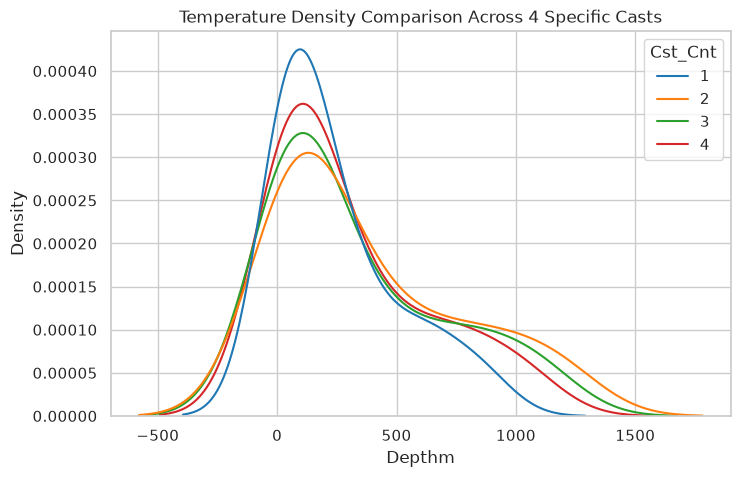

In [129]:
# Select 4 specific casts
selected_casts = df['Cst_Cnt'].unique()[:4]
subset = df[df['Cst_Cnt'].isin(selected_casts)]

plt.figure(figsize=(8, 5))
sns.kdeplot(data=subset, x="Depthm", hue="Cst_Cnt", palette="tab10")
plt.title("Temperature Density Comparison Across 4 Specific Casts")
plt.show()

In [ ]:
# Month / Day must be present for OHE - drop rare rows still missing them
before = len(model_df)
model_df = model_df.dropna(subset=["Month", "Day", "Line", "Station", "Sta_ID"]).copy()
model_df["Month"] = model_df["Month"].astype(int)
model_df["Day"] = model_df["Day"].astype(int)
print(f"Dropped {before - len(model_df):,} rows missing Month/Day/Line/Station")
print(f"Modeling rows: {len(model_df):,}")

# One-hot encode Month and Day
month_ohe = pd.get_dummies(model_df["Month"], prefix="Month")
day_ohe = pd.get_dummies(model_df["Day"], prefix="Day")
model_df = pd.concat([model_df, month_ohe, day_ohe], axis=1)

MONTH_COLS = month_ohe.columns.tolist()
DAY_COLS = day_ohe.columns.tolist()
model_df[MONTH_COLS + DAY_COLS] = model_df[MONTH_COLS + DAY_COLS].astype(float)
print(f"Month OHE cols: {len(MONTH_COLS)}, Day OHE cols: {len(DAY_COLS)}")

# Feature sets
PHYSICAL_CONTINUOUS = ["T_degC", "Depthm", "R_Depth", "R_DYNHT", "Line", "Station", "NSM"]
CHEMICAL = ["Phaeop", R_OXY_UMOL, OXY_UMOL, "O2ml_L", "O2Sat", "SiO3uM", "NO3uM"]

physical_features = PHYSICAL_CONTINUOUS + MONTH_COLS + DAY_COLS
chemical_physical_features = physical_features + CHEMICAL

print(f"Physical feature count: {len(physical_features)}")
print(f"Chemical+physical feature count: {len(chemical_physical_features)}")

## 6. Per-station train / test split

For **each** `Sta_ID`, hold out ~20% of that station's bottles for test (so every station with >=2 samples contributes to both sets). Random row splits are not used.


In [52]:
def station_train_test_split(frame, station_col="Sta_ID", test_size=0.2, random_state=RANDOM_STATE):
    """Split recordings within each station (not a global random split)."""
    rng = np.random.RandomState(random_state)
    train_idx, test_idx = [], []

    for _, group in frame.groupby(station_col):
        idx = group.index.to_numpy()
        if len(idx) == 1:
            train_idx.append(idx[0])
            continue
        n_test = max(1, int(round(len(idx) * test_size)))
        n_test = min(n_test, len(idx) - 1)  # keep >=1 in train
        chosen = rng.choice(idx, size=n_test, replace=False)
        test_idx.extend(chosen.tolist())
        train_idx.extend(np.setdiff1d(idx, chosen).tolist())

    return frame.loc[train_idx].copy(), frame.loc[test_idx].copy()

train_df, test_df = station_train_test_split(model_df)

print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")
print(f"Stations in train: {train_df['Sta_ID'].nunique()} | in test: {test_df['Sta_ID'].nunique()}")
print(
    f"Stations in both: {len(set(train_df['Sta_ID']) & set(test_df['Sta_ID']))}"
)

y_train = train_df["ChlorA"]
y_test = test_df["ChlorA"]

X_train_phys = train_df[physical_features]
X_test_phys = test_df[physical_features]
X_train_both = train_df[chemical_physical_features]
X_test_both = test_df[chemical_physical_features]

print("Physical X_train:", X_train_phys.shape, "| Both X_train:", X_train_both.shape)

Train: 196,481 | Test: 49,185
Stations in train: 1052 | in test: 896
Stations in both: 896
Physical X_train: (196481, 50) | Both X_train: (196481, 57)


## 7. Train all models (`_train_all_models.py`)

Train **all 10 regressors** with **`GridSearchCV`** on both feature sets:

1. **Physical only** - T_degC, Depthm, R_Depth, R_DYNHT, Line, Station, NSM, Month/Day OHE
2. **Physical + chemical** - above + Phaeop, oxygen, SiO3uM, NO3uM

Results are checkpointed to `model_results/` after each model (~5-10 min total).


In [53]:
def make_models_and_params():
    """Each model is wrapped in GridSearchCV with an explicit hyperparameter grid."""
    return {
        "Linear Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", LinearRegression())]),
            {"model__fit_intercept": [True, False]},
        ),
        "Ridge Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Ridge())]),
            {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        ),
        "Lasso Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Lasso(max_iter=8000))]),
            {"model__alpha": [0.001, 0.01, 0.1, 1.0]},
        ),
        "ElasticNet Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", ElasticNet(max_iter=8000))]),
            {"model__alpha": [0.01, 0.1, 1.0], "model__l1_ratio": [0.2, 0.5, 0.8]},
        ),
        "Polynomial Regression": (
            Pipeline([
                ("poly", PolynomialFeatures(include_bias=False)),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]),
            {"poly__degree": [2, 3], "model__alpha": [1.0, 10.0, 100.0]},
        ),
        "Decision Tree Regressor": (
            Pipeline([("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
            {"model__max_depth": [3, 5, 10, 20, None]},
        ),
        "Random Forest Regressor": (
            Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
            {"model__n_estimators": [50, 100, 200]},
        ),
        "Gradient Boosting Regressor": (
            Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
            {"model__learning_rate": [0.01, 0.05, 0.1], "model__n_estimators": [100, 200]},
        ),
        "Support Vector Regressor (SVR)": (
            Pipeline([("scaler", MinMaxScaler()), ("model", SVR())]),
            {"model__C": [0.1, 1.0, 10.0], "model__kernel": ["linear", "rbf"]},
        ),
        "K-Nearest Neighbors Regressor": (
            Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsRegressor(n_jobs=-1))]),
            {"model__n_neighbors": [3, 5, 7, 11]},
        ),
    }


def evaluate(y_true, y_pred):
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }


def train_model_zoo(X_train, y_train, X_test, y_test, label, svr_max_rows=8000):
    """GridSearchCV over all 10 models; checkpoint metrics CSV after each fit."""
    results = []
    fitted = {}
    models = make_models_and_params()

    for name, (pipe, params) in models.items():
        print(f"[{label}] Training {name} ...", flush=True)
        t1 = time.time()
        Xt, yt = X_train, y_train
        X_eval = X_test

        # Polynomial: continuous physical cols only (skip Month/Day OHE)
        if name == "Polynomial Regression":
            cont_cols = [c for c in PHYSICAL_CONTINUOUS if c in X_train.columns]
            Xt, yt = X_train[cont_cols], y_train
            X_eval = X_test[cont_cols]

        # SVR: subsample for tractable runtime
        if "SVR" in name and len(Xt) > svr_max_rows:
            sample_idx = yt.sample(svr_max_rows, random_state=RANDOM_STATE).index
            Xt = Xt.loc[sample_idx]
            yt = yt.loc[sample_idx]
            print(f"  (SVR subsampled to {svr_max_rows})", flush=True)

        # KNN: subsample train for speed at this scale
        if "K-Nearest" in name and len(Xt) > 30000:
            sample_idx = yt.sample(30000, random_state=RANDOM_STATE).index
            Xt = Xt.loc[sample_idx]
            yt = yt.loc[sample_idx]
            print("  (KNN subsampled to 30000 train rows)", flush=True)

        grid = GridSearchCV(
            estimator=pipe,
            param_grid=params,
            cv=3,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True,
            return_train_score=True,
        )
        grid.fit(Xt, yt)
        best = grid.best_estimator_
        pred = best.predict(X_eval)
        metrics = evaluate(y_test, pred)

        row = {
            "feature_set": label,
            "model": name,
            **metrics,
            "best_params": json.dumps(grid.best_params_),
            "best_cv_rmse": float(-grid.best_score_),
            "seconds": round(time.time() - t1, 1),
        }
        results.append(row)
        fitted[name] = best

        print(
            f"  -> R2={metrics['R2']:.4f} RMSE={metrics['RMSE']:.4f} "
            f"MAE={metrics['MAE']:.4f} ({row['seconds']}s) params={grid.best_params_}",
            flush=True,
        )
        pd.DataFrame(results).to_csv(OUT_DIR / f"metrics_{label}.csv", index=False)

    return pd.DataFrame(results), fitted

### 7.1 Train all models on both feature sets


In [53]:
# --- train physical-only, then physical + chemical (same as _train_all_models.py) ---
phys_metrics, phys_models = train_model_zoo(
    X_train_phys, y_train, X_test_phys, y_test, label="physical"
)
both_metrics, both_models = train_model_zoo(
    X_train_both, y_train, X_test_both, y_test, label="phys+chem"
)

all_metrics = pd.concat([phys_metrics, both_metrics], ignore_index=True)
all_metrics.to_csv(OUT_DIR / "metrics_all.csv", index=False)
print("\nSaved:", OUT_DIR / "metrics_all.csv")

print("\n=== Physical-only (sorted by R2) ===")
display(
    phys_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

print("\n=== Physical + chemical (sorted by R2) ===")
display(
    both_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

[physical] Training Linear Regression ...
  -> R2=0.1411 RMSE=1.1295 MAE=0.4759 (4.7s) params={'model__fit_intercept': False}
[physical] Training Ridge Regression ...
  -> R2=0.1342 RMSE=1.1340 MAE=0.4747 (4.7s) params={'model__alpha': 100.0}
[physical] Training Lasso Regression ...
  -> R2=0.1339 RMSE=1.1342 MAE=0.4700 (3.5s) params={'model__alpha': 0.001}
[physical] Training ElasticNet Regression ...
  -> R2=0.1094 RMSE=1.1501 MAE=0.4448 (3.9s) params={'model__alpha': 0.01, 'model__l1_ratio': 0.2}
[physical] Training Polynomial Regression ...
  -> R2=0.2222 RMSE=1.0748 MAE=0.4307 (4.1s) params={'model__alpha': 100.0, 'poly__degree': 2}
[physical] Training Decision Tree Regressor ...
  -> R2=0.4171 RMSE=0.9304 MAE=0.2665 (3.6s) params={'model__max_depth': 10}
[physical] Training Random Forest Regressor ...



KeyboardInterrupt


KeyboardInterrupt



### 7.2 Compare feature sets


In [ ]:
phys_idx = phys_metrics.set_index("model")
both_idx = both_metrics.set_index("model")

compare = phys_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys)").join(
    both_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys+chem)")
)
compare["R2_lift"] = compare["R2 (phys+chem)"] - compare["R2 (phys)"]
compare = compare.sort_values("R2 (phys+chem)", ascending=False)
display(compare)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(compare))
w = 0.35
ax.bar(x - w / 2, compare["R2 (phys)"], width=w, label="Physical only")
ax.bar(x + w / 2, compare["R2 (phys+chem)"], width=w, label="Physical + chemical")
ax.set_xticks(x)
ax.set_xticklabels(compare.index, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Test R2")
ax.set_title("ChlorA regression - physical vs physical+chemical")
ax.legend()
ax.axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

# Feature importance from best Random Forest (phys+chem)
tree_name = "Random Forest Regressor"
if tree_name in both_models:
    rf = both_models[tree_name].named_steps["model"]
    imp = (
        pd.Series(rf.feature_importances_, index=chemical_physical_features)
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    imp.head(20).sort_values().plot(
        kind="barh", ax=ax, color=sns.color_palette("colorblind")[0]
    )
    ax.set_xlabel("Importance")
    ax.set_title(f"{tree_name} - top 20 feature importances (phys+chem)")
    plt.tight_layout()
    plt.show()
    display(imp.head(15).to_frame("importance"))

### 7.3 Load saved results (optional)

If you already ran training (or `_train_all_models.py`), load the CSV instead of re-fitting.


In [ ]:
# Uncomment to reload without retraining:
# all_metrics = pd.read_csv(OUT_DIR / "metrics_all.csv")
# phys_metrics = all_metrics[all_metrics["feature_set"] == "physical"].copy()
# both_metrics = all_metrics[all_metrics["feature_set"] == "phys+chem"].copy()
# display(all_metrics.sort_values(["feature_set", "R2"], ascending=[True, False]))

display(pd.read_csv(OUT_DIR / "metrics_all.csv").sort_values(
    ["feature_set", "R2"], ascending=[True, False]
))